# IS4487 Week 10 - Assignment

### Outline

Our Goals with this Project:

1. Import and review the data
2. Perform EDA and Clean Data
3. Fit a model
4. Test the accuracy of the model
6.  Use the model to predict on a new dataset (without the target)

<a href="https://colab.research.google.com/github/Stan-Pugsley/is_4487_base/blob/main/Assignments/assignment_10_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Business Context AdviseInvest
You work on a small team of data analysts at AdviseInvest, a venture-backed startup. The Director of Sales at AdviseInvest has approached your team asking for help solving a staffing problem.

### The Company
The company's mission is to provide tools and support to help ordinary people gain control of their personal finances. The company leverages technology to provide affordable financial advice to a national client base.

Customers who reach AdviseInvest's website go through five steps:

- Open an account.
- Complete a customer profile form with basic information about their background and finances.
- Schedule a free phone conversation with a sales representative during a 1-hour window of time.
- Attend the free phone conversation.
- Buy a financial plan.
- There are three types of financial plans: Beginner, Intermediate, and Advanced. Each is sold at a different price, and there are varying degrees of personalization. After a customer purchases a financial plan, the customer is assigned a financial planner who helps determine the customer's goals and advises the customer on spending decisions.

### The Problem
Some customers are lost at each stage of the process. Steps 3 and 4 are particularly challenging because approximately 50% of those who schedule a phone conversation fail to pick up the call. This leads to inefficiencies from a staffing perspective.

AdviseInvest has 4 sales reps on staff during each particular 1-hour window. Each of the 4 reps is assigned 2 prospective customers per hour, which means that the company schedules a total of 8 phone calls per hour. The calls are outgoing: sales reps call customers who scheduled a phone conversation during that hour window.

Unfortunately, as noted above, many of the customers who scheduled a call do not answer. As a consequence, sales reps are often left underutilized. Moreover, they are underutilized unevenly. For example, it is possible that one sales rep will not do any sales calls during that hour, whereas another will be busy the entire hour with two calls. Sales reps have nothing to do when customers do not answer the scheduled phone call.

### AdviseInvest Data Dictionary


| Variable | Description | Type | Code |
|:---|:---|:---|:---|
| customer_id | Unique customer identifier | Numeric | |
| Answered | Customer response | Binary | 0: customer did not answer scheduled call; 1: customer answered scheduled call |
| Income | Customer income in US dollars | Numeric | |
| Female | Customer gender | Binary | 0: male; 1: female |
| Age | Age in years | Numeric | |
| Job | Nature of job | Categorical | 0 : unemployed; 1 : entry level position; 2 : midlevel position; 3 : management/ self-employed/ highly qualified employee/ officer |
| Num_dependents | Number of people for whom the customer provides maintenance | Numeric | |
| Rent | Customer rents | Binary | 0: no; 1: yes |
| Own_res | Customer owns residence | Binary | 0: no; 1: yes |
| New_car | Recent new car purchase | Binary | New car purchase in the last 3 months: 0: no, 1: yes |
| Chk_acct | Checking account status | Categorical | 0 : no checking account; 1: checking < 200 USD; 2 : 200 < checking < 2000 USD; 3: 2000 < checking < 35000 USD; 4: >= 3500 USD |
| Sav_acct | Average balance in savings account | Categorical | 0 : no savings account; 1 : 100 <= savings < 500 USD; 2 : 500 <= savings < 2000 USD; 3 : 2000 < savings < 35000 USD; 4: >= 3500 USD |
| Num_accts | Number of accounts owned by customer | Numeric | |
| Mobile | Mobile phone | Binary | 0: customer provided non‐mobile phone for follow‐up call; 1: customer provided mobile phone for follow‐up call |
| Product | Type of product purchased after conversation with sales rep | Categorical | 0: customer did not answer call; 1: customer answered but did not purchase a product; 2: customer answered and purchased Beginner plan; 3: customer answered and purchased Intermediate plan; 4: customer answered and purchased Advanced plan |

### Load Libraries

Import the libraries you will need, such as:
- Pandas
- Sklearn (including DecisionTreeClassifier, RandomForestClassifier and GradingBoostingClassifier)
- Matplotlib


In [25]:
import pandas as pd, seaborn as sns, matplotlib.pyplot as plt
from sklearn import tree, ensemble, metrics, model_selection


## Step 1: Initial Data Understanding

### Do the following:
 - Import data from the AdviseInvest historical dataset into a dataframe (in GitHub go to the DataSets folder and look for `adviseinvest_historical_data.csv`).  The GitHub page is https://github.com/Stan-Pugsley/is_4487_base/tree/main/DataSets
 - Describe or profile the dataframe
 - Look for any outliers, missing values, or duplicates

In [26]:
df = pd.read_csv('https://raw.githubusercontent.com/Stan-Pugsley/is_4487_base/refs/heads/main/DataSets/adviseinvest_historical_data.csv')
df.describe()

,customer_id,answered,income,age,job,num_dependents,rent,own_res,new_car,chk_acct,sav_acct,num_accts,mobile,product
count,29504.000000,29504.000000,29504.000000,29504.000000,29504.000000,29504.000000,29504.000000,29504.000000,29502.000000,29504.000000,29504.000000,29504.000000,29504.000000,29504.000000
mean,14850.475563,0.546638,33766.893303,34.773454,1.915401,1.140998,0.210412,0.681128,0.240797,1.468547,0.956616,2.458345,0.091106,1.535792
std,8517.254310,0.497829,29379.202710,11.369865,0.658183,0.348025,0.407608,0.466047,0.427575,1.234727,1.483946,19.497380,0.287765,1.625916
min,99.000000,0.000000,-65600.000000,19.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,7474.750000,0.000000,13550.000000,26.000000,2.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.000000,0.000000,0.000000
50%,14850.500000,1.000000,23310.000000,32.000000,2.000000,1.000000,0.000000,1.000000,0.000000,1.000000,0.000000,2.000000,0.000000,1.000000
75%,22226.250000,1.000000,41690.000000,40.000000,2.000000,1.000000,0.000000,1.000000,0.000000,3.000000,2.000000,3.000000,0.000000,3.000000
max,29602.000000,1.000000,159450.000000,132.000000,3.000000,2.000000,1.000000,1.000000,1.000000,3.000000,4.000000,3345.000000,1.000000,4.000000


In [28]:
print("Missing values:\n", df.isnull().sum()[df.isnull().sum() > 0])
print("Duplicate rows:", df.duplicated().sum())
print(df['female'].value_counts())

Missing values:
 new_car    2
dtype: int64
Duplicate rows: 3
female
0    27903
1     1600
M        1
Name: count, dtype: int64


### Reflection:
1.1. What stands out in the initial preview? Any columns or rows that seem unusual?

### ✍️ Your Response: 🔧
1.1 The data has 29,504 customers and 15 columns. Income has a negative value (-65,600), age has a max of 132, and num_accts has a max of 3,345. The female column has one “M”, new_car has 2 missing values, and there are 3 duplicate rows. Product is only filled in after a customer answers, so it can’t predict answering.



# Step 2: Data Preparation

## 2.1: Data Cleanup

### Do the following:
- 2.1 Check for and remove any outliers
- 2.2 Consider fixing any missing data (should you delete the record or impute the value?)
- 2.3 remove any variables, like customer_id, that are not helpful in predicting the target variable (hint: are there any variables that are available only AFTER the customer has answered, and wouldn't be useful in predicting?)
- 2.4 Clean up the data and put it in a new dataframe named "df_clean"


In [29]:
df_clean = df.drop_duplicates().dropna()
df_clean = df_clean[df_clean['female'].isin(['0', '1']) & (df_clean['income'] > 0) & df_clean['age'].between(18, 100) & (df_clean['num_accts'] <= 10)]
df_clean = df_clean.drop(columns=['customer_id', 'product']).reset_index(drop=True)
df_clean.shape

(29494, 13)

### Reflection:
2.5  Explain the steps that you took to clean outliers and missing data.  Why did you chose the approach that you used?

2.6  Which variables did you remove, and why?

### ✍️ Your Response: 🔧
2.5 I removed the 3 duplicates and the 2 rows with missing new_car (too few to be worth imputing). I also removed impossible values: income at or below 0, age over 100, the “M” in female, and more than 10 accounts. I used simple rules because these values are impossible, not just unusual. In total 10 rows were removed.

2.6 I removed customer_id because it is only an identifier. I removed product because it is only known after the customer answers, so it would leak the answer.

## 2.2: Standardize variables

### Do the following:
 - Change "answered" to a boolean (true/false) type
 - Convert any variables that should be an integer into an integer

In [30]:
df_clean = df_clean.astype({'answered': bool, 'female': int, 'new_car': int})
df_clean.dtypes

,0
answered,bool
income,int64
female,int64
age,int64
job,int64
num_dependents,int64
rent,int64
own_res,int64
new_car,int64
chk_acct,int64


## 2.3 Convert variables

### Do the following:
- convert at least 3 variables to categorical where that data type is appropriate

In [31]:
df_clean = df_clean.astype({'job': 'category', 'chk_acct': 'category', 'sav_acct': 'category'})
df_clean.dtypes

,0
answered,bool
income,int64
female,int64
age,int64
job,category
num_dependents,int64
rent,int64
own_res,int64
new_car,int64
chk_acct,category


# Step 3: Exploratory Data Analysis (EDA)

### Do the following:
- Explore the relationships between the target and independent variables
- Create at least five charts to show the relationships, using different chart types that are approriate to the analysis
- Ensure that all charts are clearly labeled and formatted



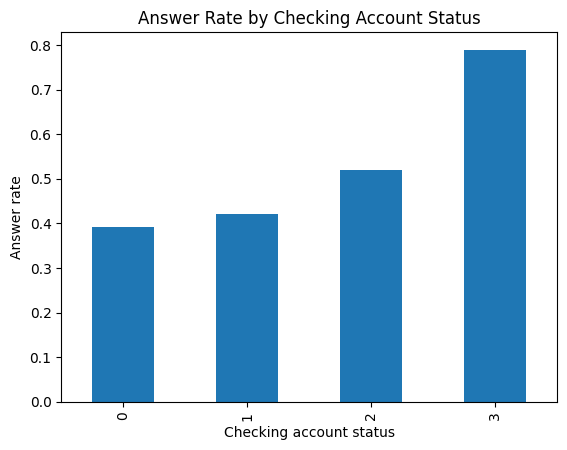

In [32]:
df_clean.groupby('chk_acct', observed=True)['answered'].mean().plot.bar(title='Answer Rate by Checking Account Status', xlabel='Checking account status', ylabel='Answer rate')
plt.show()


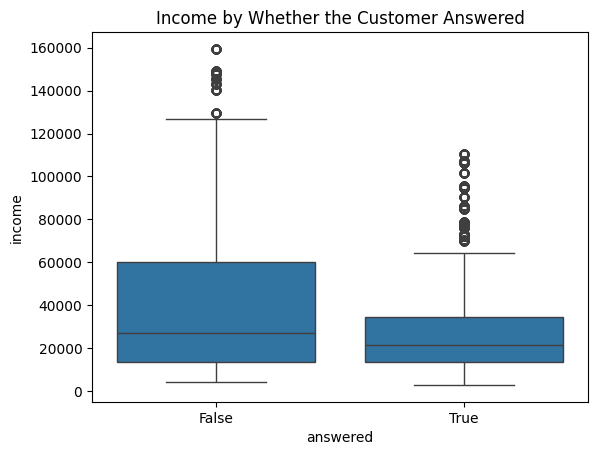

In [33]:
sns.boxplot(data=df_clean, x='answered', y='income')
plt.title('Income by Whether the Customer Answered')
plt.show()

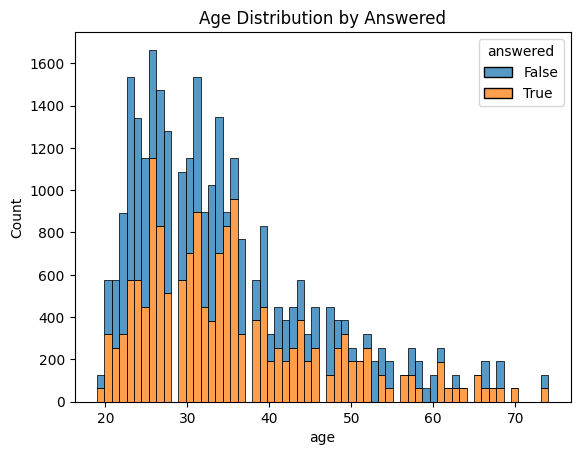

In [35]:
sns.histplot(data=df_clean, x='age', hue='answered', multiple='stack')
plt.title('Age Distribution by Answered')
plt.show()

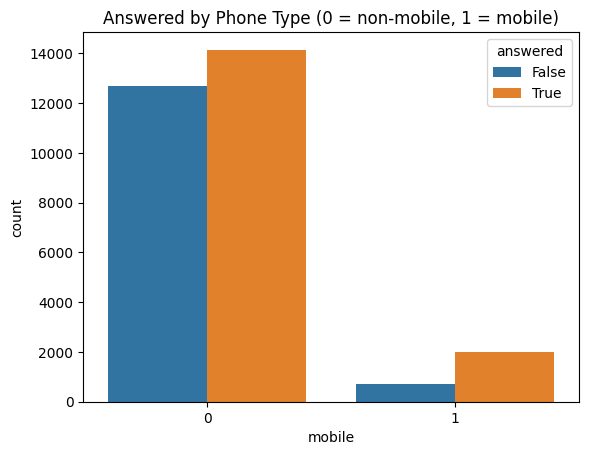

In [34]:
sns.countplot(data=df_clean, x='mobile', hue='answered')
plt.title('Answered by Phone Type (0 = non-mobile, 1 = mobile)')
plt.show()

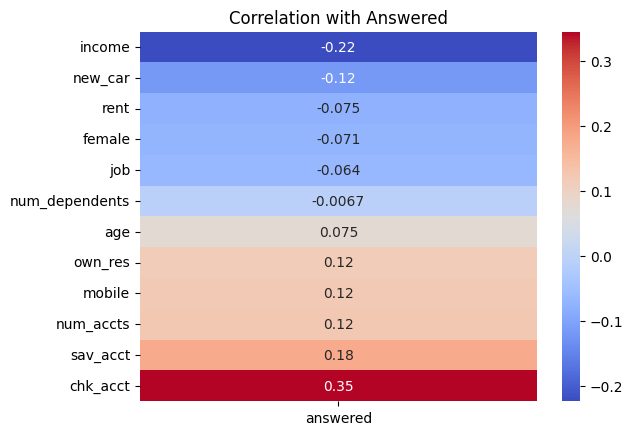

In [36]:
sns.heatmap(df_clean.astype(int).corr()[['answered']].drop('answered').sort_values('answered'), annot=True, cmap='coolwarm')
plt.title('Correlation with Answered')
plt.show()

### Reflection:
3.6. Which variables show the strongest relationship with the target variable?

3.7. Did you find any variables that have a weak relationship with the target variable?  Should they be removed?

### ✍️ Your Response: 🔧
3.6. Checking account status is strongest (correlation 0.35), followed by income (-0.22) and savings account status (0.18).

3.7.  num_dependents is nearly zero (-0.007), and rent, female, job, and age are also weak. I kept them because tree models ignore unhelpful variables, and age was still a top feature in the random forest and gradient boosting models.

## Step 4: Modeling

Start with the baseline.  If we use no model at all, how good is our chance of predicting someone leaving?  Use a calculation to find the chances of someone leaving.

### Do the following:
4.1 Calculate the base probability of answering  

In [38]:
base_prob = df_clean['answered'].mean()
print(f"Base probability of answering: {base_prob:.4f}")

Base probability of answering: 0.5467


## 4.2: Split the training and testing datasets

### Do the following:
- split df_clean using train_test_split function

Notes:
- all remaining variables except answered should be in the x variable
- answered is in the y variable


In [40]:
X = pd.get_dummies(df_clean.drop(columns='answered'))
y = df_clean['answered']
X_train, X_test, y_train, y_test = model_selection.train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print(X_train.shape, X_test.shape)

(23595, 22) (5899, 22)


## 4.3: Create a Decision Tree

### Do the following:
- Create a tree
- Display (visualize) the tree

Notes:
- Use all available attributes (except those that were eliminated in step 3)
- It is recommended to use the type "entropy" and a max_depth of 4

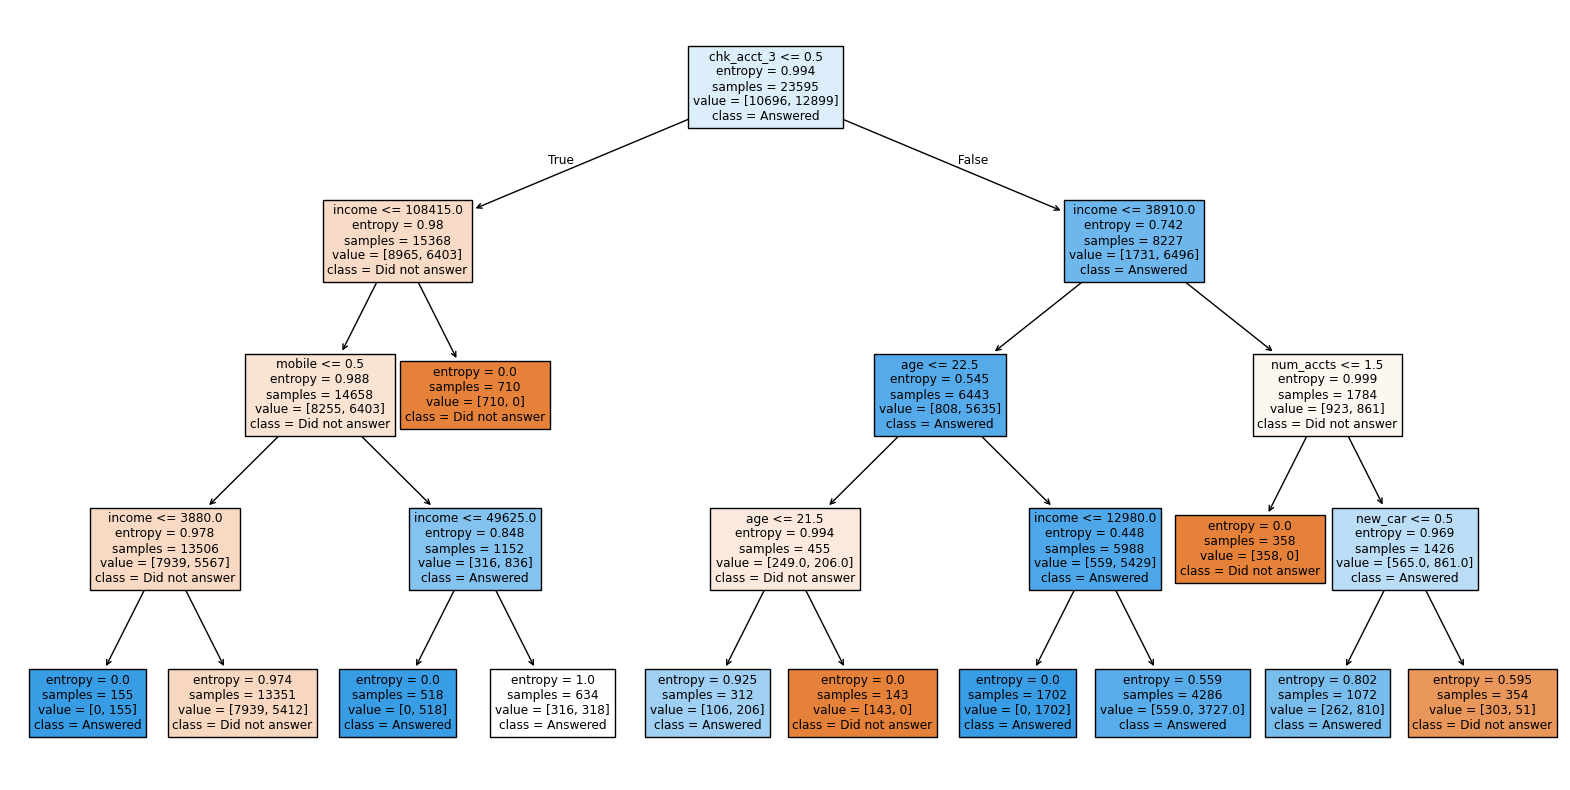

In [41]:
dt = tree.DecisionTreeClassifier(criterion='entropy', max_depth=4, random_state=42).fit(X_train, y_train)
plt.figure(figsize=(20, 10))
tree.plot_tree(dt, feature_names=X.columns, class_names=['Did not answer', 'Answered'], filled=True)
plt.show()

## 4.4: Calculate the accuracy

This should be better than the base probability, or you have failed in your objective

### Do the following:
- Calculate the probability for your tree

In [42]:
tree_pred = dt.predict(X_test)
print("Tree accuracy:", metrics.accuracy_score(y_test, tree_pred))
print("Improvement over baseline:", metrics.accuracy_score(y_test, tree_pred) - base_prob)

Tree accuracy: 0.7155450076284116
Improvement over baseline: 0.1688575457717627


### Reflection:
1. What is the difference between the probability from the model compared to the base probability?
2. Is this difference a significant amount for the business?  

### ✍️ Your Response: 🔧
1. The tree’s accuracy was 71.6% versus a 54.7% baseline, about 16.9 points better.

2. Yes, it correctly predicts about 7 out of 10 customers instead of about 5 out of 10, though accuracy alone doesn’t decide profit.


## 4.5: Confusion Matrix

### Do the following
- Create a confusion matrix

This will show false positives, true positives, etc.

In [44]:
print(metrics.confusion_matrix(y_test, tree_pred))


[[2381  293]
 [1385 1840]]


Create a more visual, interpretable version of the matrix (hint - try using Seaborn Heatmap)

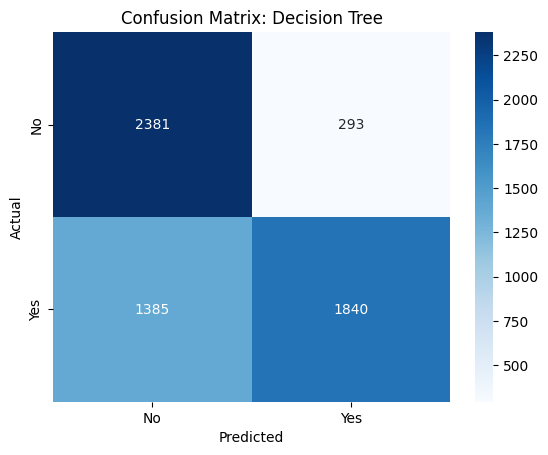

In [45]:
ax = sns.heatmap(metrics.confusion_matrix(y_test, tree_pred), annot=True, fmt='d', cmap='Blues', xticklabels=['No', 'Yes'], yticklabels=['No', 'Yes'])
ax.set(xlabel='Predicted', ylabel='Actual', title='Confusion Matrix: Decision Tree')
plt.show()

## 4.6 Check for Overfitting and Underfitting

A model may perform very well on its training data but poorly on new data. This is called **overfitting**. A model may also perform poorly on both training and test data. This is called **underfitting**.

Remember that we can evaluate fit with these guidelines:
- **Overfit:** Training accuracy is much higher than test accuracy.
- **Underfit:** Both training and test accuracy are low.
- **Balanced:** Training and test accuracy are fairly close, and test accuracy is meaningfully better than the baseline probability.


### Do the following:

- Calculate the accuracy of your decision tree on the training data.
- Compare it to the accuracy on the testing data.
- Calculate the difference between the two accuracy scores.

In [46]:
train_acc, test_acc = dt.score(X_train, y_train), dt.score(X_test, y_test)
print("Train:", train_acc, "Test:", test_acc)
print("Difference:", train_acc - test_acc)

Train: 0.7157872430599703 Test: 0.7155450076284116
Difference: 0.00024223543155876825


### Reflection:
1. Does your model appear to be overfit, underfit, or reasonably balanced? Explain using the training and testing accuracy scores.
2. If the model is overfit, what changes could you make to simplify it?
3. If the model is underfit, what changes could you make to allow it to identify more patterns?
### ✍️ Your Response: 🔧
1. The model is reasonably balanced, if slightly underfit. Training accuracy was 71.58% and test accuracy was 71.55%, only 0.02 points apart, and both are well above the baseline.
2. It is not overfit, so it doesn’t need to be simplified.
3. I could increase max_depth, which I did in the tuning step (accuracy rose to 77.8%).

# Step 5: Evaluate the Model

**Assumptions**

One of the simplifying assumptions we will make in this project is that all the customers who answer the phone will purchase a product. (This assumption is actually verified by the data.) To model "answered" in this case is therefore equivalent to modeling "purchased."

There are costs and benefits in this case. We will assume that customers purchase a product for 100 dollars. This was the average cost of AdviseInvest products, according to the Director of Sales.  Also, as we learned in the interview, the agent time to make the sale is worth 25 dollars. Profit would therefore be \$75 dollars for an answered call and a purchase. In sum:

**Benefit**: True positive. The customer is predicted to answer, does answer, and purchases a product for 100 dollars for a profit of 100 - 25 = 75.

**Cost**: False positive. The customer is predicted to answer, but does not answer, so there is a loss of 25. (We assume the agent cannot schedule another call at the last minute, or spends the entire time slot trying to make the call.)

When you create a calculation you can use:
- True answered * 75 -> These people purchased
- False answered * 25 -> You can't schedule another call

For this exercise, we propose that customers who are not predicted to answer will not be called, so there would be no benefits and no costs for them.  

### Do the following:
Calculate the Profit Using the Model

In [47]:
tn, fp, fn, tp = metrics.confusion_matrix(y_test, tree_pred).ravel()
model_profit = tp * 75 - fp * 25
print("Profit using the model:", model_profit)

Profit using the model: 130675


## 5.2 Compare to the Default Profit

### Do the following:
- Calculate the profit (revenue - costs) that would be expected if all customers are called

Notes:
- We can consider this a baseline case for profit since it does not require a model
- In other words, to calculate profit in this baseline scenario treat the customers who answer as true positives treat the customers who do not answer as false positives.

In [48]:
base_profit = y_test.sum() * 75 - (~y_test).sum() * 25
print("Profit if all customers are called:", base_profit)
print("Model minus call-everyone:", model_profit - base_profit)

Profit if all customers are called: 175025
Model minus call-everyone: -44350


### Reflection:
1. What is the difference in profit between calling all customers and calling customers that are recommended by the model?
2. Is this a significant amount for the business?  

### ✍️ Your Response: 🔧
1. Calling everyone earns 175,025$ and the model earned 130,675$ so the model earned about 44k$ less.

2. Yes, but in the wrong direction. The tree skipped 1385 customers who would have answered ($75 each) to avoid 2,381 wasted called (about $25 each)


## 5.3 Tune the Model

### Do the Following
- Create a new version of the tree with new parameters
- Calculate a new probability

Notes:
- Adjust the size or shape of the tree, then test the accuracy
- Keep changing these parameters until you end up with a tree with accuracy that is better than the initial model

In [49]:
dt_tuned = tree.DecisionTreeClassifier(criterion='entropy', max_depth=8, random_state=42).fit(X_train, y_train)
tuned_pred = dt_tuned.predict(X_test)
print("Tuned tree accuracy:", metrics.accuracy_score(y_test, tuned_pred))

Tuned tree accuracy: 0.7775894219359213


In [66]:
tree_accuracy = metrics.accuracy_score(y_test, tuned_pred)
tn, fp, fn, tp = metrics.confusion_matrix(y_test, tuned_pred).ravel()
tree_tp, tree_fp, tree_profit = tp, fp, tp * 75 - fp * 25

## 5.4 Create a Random Forest Model

A random forest combines the predictions of many decision trees. Each tree uses a different random sample of the training data and considers a random subset of variables at each split. Combining the trees can produce a more stable prediction than relying on one tree.

### Do the following:
- Import and create a RandomForestClassifier model.
- Use at least 100 trees (n_estimators=100) and set random_state=42.
- Fit the model using the same training data used for the decision tree.
- Predict whether customers in the test data will answer.
- Calculate the test accuracy and display a confusion matrix.
- Create a feature-importance chart for the random forest.

In [50]:
rf = ensemble.RandomForestClassifier(n_estimators=100, random_state=42).fit(X_train, y_train)
rf_pred = rf.predict(X_test)

In [51]:
rf_accuracy = metrics.accuracy_score(y_test, rf_pred)
tn, fp, fn, tp = metrics.confusion_matrix(y_test, rf_pred).ravel()
rf_tp, rf_fp, rf_profit = tp, fp, tp * 75 - fp * 25
print("RF accuracy:", rf_accuracy, "\n", metrics.confusion_matrix(y_test, rf_pred))

RF accuracy: 1.0 
 [[2674    0]
 [   0 3225]]


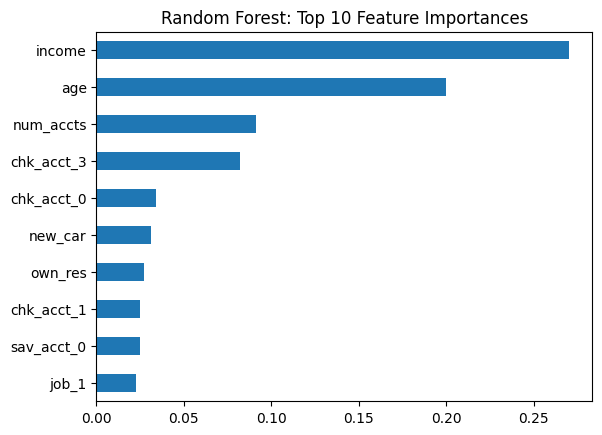

In [52]:
pd.Series(rf.feature_importances_, index=X.columns).nlargest(10).sort_values().plot.barh(title='Random Forest: Top 10 Feature Importances')
plt.show()

### Reflection:
1. Did the random forest have higher or lower test accuracy than your tuned decision tree?
2. Which variables were most important in the random forest? Were they the same variables that appeared near the top of your decision tree?

### ✍️ Your Response: 🔧
1. The random forest had much higher accuracy (100%) than the tuned tree (77.8%). A perfect score is suspicious and may mean the model is memorizing the data.

2. Income and age were most important, followed by num_accts and chk_acct_3. These are mostly the same variables near the top of my decision tree.


### 5.5 Create a Gradient Boosting Model

Gradient boosting also combines many small trees, but it builds them in sequence. Each new tree attempts to improve the mistakes made by the earlier trees. This can create a strong predictive model, although its settings should be chosen carefully to avoid overfitting.

### Do the following:

- Import and create a GradientBoostingClassifier model.
- Start with n_estimators=100, learning_rate=0.1, max_depth=3, and random_state=42.
- Fit the model using the same training data.
- Predict whether customers in the test data will answer.
- Calculate test accuracy and display a confusion matrix.
- Create a feature-importance chart for the gradient boosting model.

In [55]:
gb = ensemble.GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, max_depth=3, random_state=42).fit(X_train, y_train)
gb_pred = gb.predict(X_test)

In [54]:
gb_accuracy = metrics.accuracy_score(y_test, gb_pred)
tn, fp, fn, tp = metrics.confusion_matrix(y_test, gb_pred).ravel()
gb_tp, gb_fp, gb_profit = tp, fp, tp * 75 - fp * 25
print("GB accuracy:", gb_accuracy, "\n", metrics.confusion_matrix(y_test, gb_pred))

GB accuracy: 0.8806577385997627 
 [[2367  307]
 [ 397 2828]]


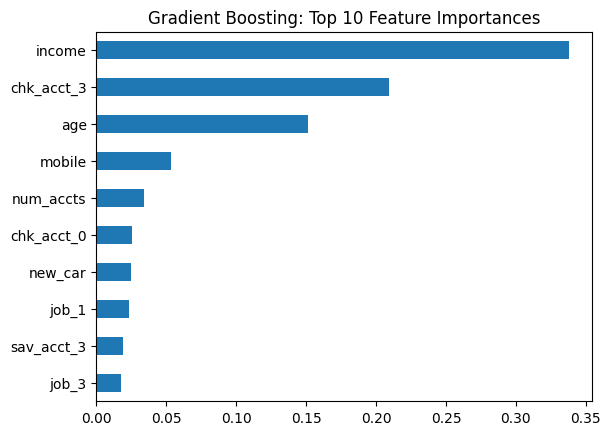

In [56]:
pd.Series(gb.feature_importances_, index=X.columns).nlargest(10).sort_values().plot.barh(title='Gradient Boosting: Top 10 Feature Importances')
plt.show()

### Reflection:

1. Which model had better test accuracy: the random forest or gradient boosting model?
2. In your own words, how does gradient boosting differ from a random forest?

### ✍️ Your Response: 🔧
1. The random forest was better (100% vs 88.1%).

2. A random forest builds many trees independently and averages them. Gradient boosting builds trees one after another, each fixing the previous trees’ mistakes.


## 5.6 Compare Models Using Accuracy and Profit

Accuracy is useful, but AdviseInvest ultimately cares about staffing and profit. Compare your tuned decision tree, random forest, and gradient boosting models using both measures.

### Do the following:
- Create a table with one row for each model.
- Include each model's test accuracy, true positives, false positives, and estimated profit.
- Calculate model profit using the same business rules from Step 5:
- profit = (true positives × 75) - (false positives × 25)
- Create a bar chart comparing the test accuracy of the three models.
- Identify the model you would recommend for use on new customer data. Your choice should consider both accuracy and profit.

In [68]:
# Example structure; replace the values with your own calculations
model_results = pd.DataFrame({
    'Model': ['Tuned Decision Tree', 'Random Forest', 'Gradient Boosting'],
    'Test Accuracy': [tree_accuracy, rf_accuracy, gb_accuracy],
    'True Positives': [tree_tp, rf_tp, gb_tp],
    'False Positives': [tree_fp, rf_fp, gb_fp],
    'Estimated Profit': [tree_profit, rf_profit, gb_profit]
})

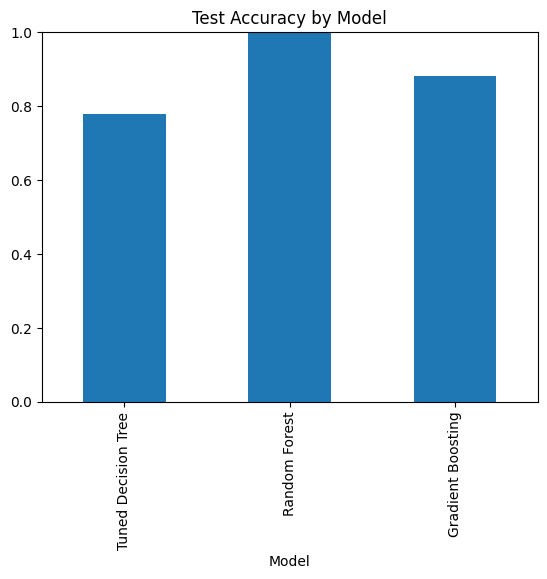

Highest profit: Random Forest


In [69]:
model_results.plot.bar(x='Model', y='Test Accuracy', ylim=(0, 1), legend=False, title='Test Accuracy by Model')
plt.show()
print("Highest profit:", model_results.loc[model_results['Estimated Profit'].idxmax(), 'Model'])

## 5.7 Apply the Best Model to New Customers

### Do the Following

- Import the "adviseinvest_new_customer_data.csv" file
- Copy and paste the applicable data cleanup and data-type conversion steps from 2.1 through 2.3.
- Make the new-customer variables match the columns used to train your models. If you used pd.get_dummies(), ensure that the new dataset has the same - dummy-variable columns as the training data.
- Using the model you recommended in Step 5.6, predict each customer's target variable by feeding the new customer data into the model.
- Predict the number of customers who will be yes/no for the target variable

In [65]:
new = pd.read_csv('https://raw.githubusercontent.com/Stan-Pugsley/is_4487_base/refs/heads/main/DataSets/adviseinvest_new_customer_data.csv')
new_clean = new.drop_duplicates().dropna().query('income > 0 and 18 <= age <= 100 and num_accts <= 10')
print(len(new), len(new_clean))

1000 1000


### Reflection:

1. Which model produced the highest estimated profit? Was it also the most accurate model?
2. Why might a business select a model with slightly lower accuracy?
3. Which model would be easiest to explain to the Director of Sales? Which model would you recommend using?

### ✍️ Your Response: 🔧
 1. The random forest had the highest profit ($241,875) and was also the most accurate. Gradient boosting was next ($204,425).

 2. A business might pick a simpler, cheaper, or easier-to-explain model, or one whose mistakes cost less. A missed customer costs $75 but an extra call only $25, so fewer missed customers can mean more profit.

 3. The decision tree is easiest to explain, but it earned the least. I recommend the random forest, with caution because the 100% accuracy is probably too good to be true. Gradient boosting is a safer second choice.






# Step 6: Conclusion

### Reflection:
6.1: Did we improve our profit using the model?  

6.2: How could the model be utilized by the business?

### ✍️ Your Response: 🔧
6.1 The first tree did not improve profit (it earned $44,350 less than calling everyone). The random forest and gradient boosting did, earning $241,875 and $204,425 versus $175,025.

6.2 AdviseInvest could score each scheduled customer before the hour, call the customers predicted to answer first, and use the predictions to plan how many reps to staff. Calling is worth it whenever the chance of answering is above 25% (a $75 gain against a $25 loss), so the business should not skip everyone the model says will not answer. The model should also be retrained as new data arrives.

## Submission Instructions
✅ Checklist:
- All code cells run without error
- All markdown responses are complete
- Submit on Canvas as instructed

In [70]:
!jupyter nbconvert --to html "assignment_10_classification.ipynb"

[NbConvertApp] WARNING | pattern 'assignment_10_classification.ipynb' matched no files
This application is used to convert notebook files (*.ipynb)
        to various other formats.


Options
The options below are convenience aliases to configurable class-options,
as listed in the "Equivalent to" description-line of the aliases.
To see all configurable class-options for some <cmd>, use:
    <cmd> --help-all

--debug
    set log level to logging.DEBUG (maximize logging output)
    Equivalent to: [--Application.log_level=10]
--show-config
    Show the application's configuration (human-readable format)
    Equivalent to: [--Application.show_config=True]
--show-config-json
    Show the application's configuration (json format)
    Equivalent to: [--Application.show_config_json=True]
--generate-config
    generate default config file
    Equivalent to: [--JupyterApp.generate_config=True]
-y
    Answer yes to any questions instead of prompting.
    Equivalent to: [--JupyterApp.answer_yes=Tr